In [8]:
import h5py

def inspectItem(name, item):
    if isinstance(item, h5py.Dataset):
        print(f"Dataset: {name} | shape={item.shape} | dtype={item.dtype}")
    else:
        print(f"Group:   {name}")

nsdminiStimuliFilePath = "/Users/justin/proj/nsdmini/nsdmini_stimuli.hdf5"
with h5py.File(nsdminiStimuliFilePath, "r") as hdfFile:
    # Show items at the root of the file.
    print("Top-level items:", list(hdfFile.keys()))

    # Walk through every group and dataset without loading the array data.
    hdfFile.visititems(inspectItem)

    # Show metadata attached to the file itself.
    print("\nFile attributes:", dict(hdfFile.attrs))

Top-level items: ['imgBrick']
Dataset: imgBrick | shape=(515, 425, 425, 3) | dtype=uint8

File attributes: {}


Image shape: (425, 425, 3), dtype: uint8


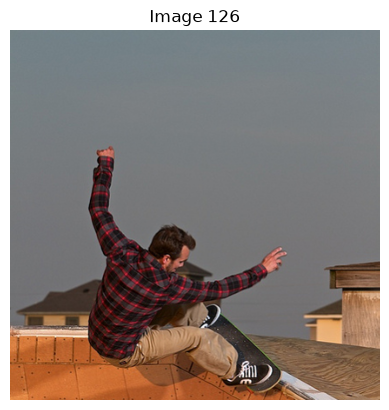

In [11]:
import h5py
import matplotlib.pyplot as plt

def loadImage(filePath, imageIndex):
    with h5py.File(filePath, "r") as hdfFile:
        dataset = hdfFile["imgBrick"]

        # Image indices are zero-based: 0 through 514.
        if not 0 <= imageIndex < dataset.shape[0]:
            raise IndexError(f"imageIndex must be between 0 and {dataset.shape[0] - 1}")

        # Load only the selected image into memory.
        return dataset[imageIndex]

# Select an image: index 9 is the 10th image.
imageIndex =125
image = loadImage(nsdminiStimuliFilePath, imageIndex)
    
print(f"Image shape: {image.shape}, dtype: {image.dtype}")

plt.imshow(image)
plt.title(f"Image {imageIndex + 1}")
plt.axis("off")
plt.show()

In [5]:
import scipy.io as sio

matData = sio.loadmat("/Users/justin/proj/nsdmini/nsdmini_expdesign.mat", simplify_cells=True)

# Show user variables, excluding MATLAB metadata.
for name, value in matData.items():
    if not name.startswith("__"):
        print(f"{name}: type={type(value).__name__}, shape={getattr(value, 'shape', None)}")

# Access a variable by its name.
data = matData["masterordering"]

masterordering: type=ndarray, shape=(1030,)
special515ix: type=ndarray, shape=(515,)
stimpattern: type=ndarray, shape=(10, 120)


In [6]:
print(data)

[135 503 512 ...  39 104 218]
